# Phase 2A · 02 · Leave-one-study-out (LOSO)

**Goal:** test the paper's random forest on studies it has never seen, one study at a time, and compare each result with the paper's Table S5.

**What this notebook shows**
- What leave-one-study-out validation is and how it differs from the cross-validation in notebook 01.
- How filtering and normalization are learned on the training studies only and then applied, frozen, to the held-out study.
- Our AUC for each of the 27 studies next to the paper's.
- A bonus check: cross-validation inside each single study, also compared with Table S5.

## Setup

This notebook starts from the raw shares of the 5,966 balanced samples (notebook 1/03), not from the finished feature matrix. Here the filter and the normalization must be learned again for every held-out study, from the other 26 only.

In [1]:
import time
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

SEED = 2000
print("SEED =", SEED)

SEED = 2000


In [2]:
def find_project_root() -> Path:
    """Walk up from the current folder until we find the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("Could not find the project root (no requirements.txt above this folder).")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "processed"
SHEETS = PROJECT_ROOT / "papers" / "spreadsheets"
FIGURES = PROJECT_ROOT / "results" / "figures"
TABLES = PROJECT_ROOT / "results" / "tables"
NOTEBOOK_PREFIX = "p2a_02"
figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{NOTEBOOK_PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

The preprocessing helpers, copied from notebook 1/03, and the forest from notebook 2A/01.

In [3]:
UNMAPPED_NAMES = [
    "UNMAPPED", "-1", "X.1", "unmapped", "Unclassified", "Unassigned",
    "UNCLASSIFIED", "unclassified", "UNASSIGNED", "unassigned",
]


def prevalence_filter(relab: pd.DataFrame, cutoff: float = 0.1) -> list[str]:
    """Genera that are non-zero in more than `cutoff` of the samples, without unmapped names (SIAMCAT's rule)."""
    prevalence = (relab > 0).mean()
    kept = prevalence[prevalence > cutoff].index
    return [genus for genus in kept if genus not in UNMAPPED_NAMES]


@dataclass
class LogStdParams:
    mean: pd.Series
    adjusted_sd: pd.Series


def fit_log_std(relab: pd.DataFrame, pseudocount: float = 1e-5, sd_quantile: float = 0.1) -> LogStdParams:
    """Learn each genus's mean and adjusted standard deviation on the log scale (SIAMCAT's log.std)."""
    logged = np.log10(relab + pseudocount)
    sd = logged.std(ddof=1)
    q = np.quantile(sd, sd_quantile)
    assert q > 0, "the 10th percentile of standard deviations must be positive"
    return LogStdParams(mean=logged.mean(), adjusted_sd=sd + q)


def apply_log_std(relab: pd.DataFrame, params: LogStdParams, pseudocount: float = 1e-5) -> pd.DataFrame:
    """Log-transform and standardize with already learned parameters."""
    logged = np.log10(relab + pseudocount)
    return (logged - params.mean) / params.adjusted_sd


def make_forest(seed: int, n_jobs: int = -1) -> RandomForestClassifier:
    return RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=n_jobs, random_state=seed)

In [4]:
relab = pd.read_parquet(PROCESSED / "relab_balanced.parquet")
labels = pd.read_csv(PROCESSED / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert relab.index.equals(labels.index), "abundances and labels must be in the same row order"

paper_s5 = pd.read_excel(SHEETS / "mmc5.xlsx", skiprows=1)
paper_loso = paper_s5[paper_s5["ML_approach"] == "LOSO"].set_index("Test")["AUC"]
paper_scv = paper_s5[paper_s5["ML_approach"] == "SCV"].set_index("Test")["AUC"]
print(f"{relab.shape[0]:,} samples, {relab.shape[1]:,} genera, {labels['Cohort'].nunique()} studies")
print(f"Table S5 has {len(paper_loso)} LOSO and {len(paper_scv)} within-study CV results")

5,966 samples, 3,803 genera, 27 studies
Table S5 has 26 LOSO and 27 within-study CV results


## 1. What leave-one-study-out tests

Notebook 01 asked: *across all studies, how well does the model separate cancer from controls?* LOSO asks a harder and more practical question: *if a new hospital sends us its samples, how well does a model trained on everyone else work there?*

For each of the 27 studies:
1. Put that study aside. It is the **held-out** study.
2. Train one forest on the other 26 studies.
3. Predict the held-out study and compute one AUC for it.

That gives 27 AUCs, one per study. The paper's text describes exactly this: "we trained classifiers on all CRC/control samples of all dataset except one and evaluated classifier performance on the held-out dataset".

## 2. Preprocessing without leakage

In notebook 01 the filter and normalization saw all samples, including the test ones. Here we do it properly, because the held-out study plays the role of a hospital we haven't met yet:

- The **prevalence filter** is computed on the 26 training studies only. The held-out study gets exactly the same columns, even if a genus would have passed the filter there.
- The **normalization** is fitted on the 26 training studies (mean and adjusted standard deviation per genus) and then applied *frozen* to the held-out study, using the training numbers. SIAMCAT calls this "frozen normalization".

In [5]:
def loso_predict(relab: pd.DataFrame, labels: pd.DataFrame, held_out: str, seed: int) -> np.ndarray:
    """Train on every study except `held_out` and return CRC probabilities for the held-out study's samples."""
    is_held_out = (labels["Cohort"] == held_out).to_numpy()
    train_relab, holdout_relab = relab[~is_held_out], relab[is_held_out]

    genera = prevalence_filter(train_relab)
    params = fit_log_std(train_relab[genera])
    train_features = apply_log_std(train_relab[genera], params)
    holdout_features = apply_log_std(holdout_relab.reindex(columns=genera), params)

    assert list(holdout_features.columns) == list(train_features.columns)
    assert np.isfinite(holdout_features.to_numpy()).all()

    model = make_forest(seed)
    model.fit(train_features, labels.loc[~is_held_out, "label"])
    return model.predict_proba(holdout_features)[:, 1]

## 3. Run all 27 studies

In [6]:
cohorts = sorted(labels["Cohort"].unique())
rows = []
start = time.perf_counter()
for cohort in cohorts:
    is_held_out = labels["Cohort"] == cohort
    probabilities = loso_predict(relab, labels, cohort, SEED)
    rows.append({
        "cohort": cohort,
        "assay": labels.loc[is_held_out, "Assay"].iloc[0],
        "n_train": int((~is_held_out).sum()),
        "n_test": int(is_held_out.sum()),
        "our_auc": roc_auc_score(labels.loc[is_held_out, "label"], probabilities),
    })
print(f"Trained {len(cohorts)} forests in {time.perf_counter() - start:.0f} s")

loso = pd.DataFrame(rows).set_index("cohort")
loso["paper_auc"] = paper_loso.reindex(loso.index)
loso["difference"] = loso["our_auc"] - loso["paper_auc"]
TABLES.mkdir(parents=True, exist_ok=True)
loso.round(4).to_csv(TABLES / "loso_auc.csv")
loso.round(3).sort_values("paper_auc")

Trained 27 forests in 30 s


,assay,n_train,n_test,our_auc,paper_auc,difference
cohort,,,,,,
HanniganGD_2018,WGS,5934,32,0.697,0.707,-0.010
YachidaS_2019,WGS,5468,498,0.739,0.745,-0.006
BaxterNT_2016,16S,5726,240,0.756,0.778,-0.022
VogtmannE_2016,WGS,5862,104,0.776,0.783,-0.007
YoungC2_2021,16S,5360,606,0.607,0.794,-0.187
YangY_2021a,16S,5264,702,0.824,0.813,0.011
OkumuraS_2021,16S,4940,1026,0.814,0.816,-0.002
ThomasAM_2019_1,WGS,5918,48,0.843,0.819,0.023
YangY_2021c,WGS,5768,198,0.816,0.819,-0.003


## 4. Compare with the paper

`DuX_2022` has no LOSO value in Table S5, so the comparison uses the other 26 studies.

In [7]:
compared = loso.dropna(subset=["paper_auc"])
mean_absolute_difference = compared["difference"].abs().mean()
correlation = compared["our_auc"].corr(compared["paper_auc"])
far_off = compared[compared["difference"].abs() > 0.05]

print(f"Mean absolute difference over {len(compared)} studies: {mean_absolute_difference:.3f}")
print(f"Correlation between our and the paper's AUCs: {correlation:.2f}")
print(f"Our mean LOSO AUC {compared['our_auc'].mean():.3f}, paper's {compared['paper_auc'].mean():.3f}")
print(f"Studies off by more than 0.05: {len(far_off)}")
far_off.round(3)

Mean absolute difference over 26 studies: 0.021
Correlation between our and the paper's AUCs: 0.85
Our mean LOSO AUC 0.835, paper's 0.851
Studies off by more than 0.05: 2


,assay,n_train,n_test,our_auc,paper_auc,difference
cohort,,,,,,
YoungC2_2021,16S,5360,606,0.607,0.794,-0.187
ZhouZ_2022,16S,5930,36,0.875,0.938,-0.063


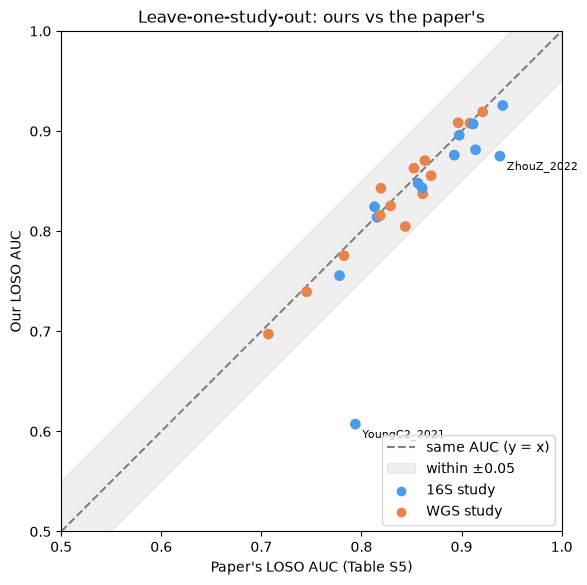

**Figure 1.** Each dot is one held-out study (26 with a value in Table S5). Our AUCs differ from the paper's by 0.021 on average (correlation 0.85). 24 studies fall inside the ±0.05 band and 2 outside. Our mean is 0.835, the paper's 0.851. The paper reports a LOSO range of 0.70 to 0.94, ours is 0.61 (YoungC2_2021) to 0.93 (DengX_2018).

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
colors = compared["assay"].map({"16S": "#4C9BE8", "WGS": "#E8834C"})
ax.scatter(compared["paper_auc"], compared["our_auc"], c=colors, s=45, zorder=3)
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", label="same AUC (y = x)")
ax.fill_between([0.5, 1], [0.45, 0.95], [0.55, 1.05], color="grey", alpha=0.12, label="within ±0.05")
for cohort, row in far_off.iterrows():
    ax.annotate(cohort, (row["paper_auc"], row["our_auc"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.scatter([], [], color="#4C9BE8", label="16S study")
ax.scatter([], [], color="#E8834C", label="WGS study")
ax.set_xlim(0.5, 1)
ax.set_ylim(0.5, 1)
ax.set_aspect("equal")
ax.set_xlabel("Paper's LOSO AUC (Table S5)")
ax.set_ylabel("Our LOSO AUC")
ax.set_title("Leave-one-study-out: ours vs the paper's")
ax.legend(loc="lower right")

show_figure(
    fig,
    "loso_vs_paper",
    f"Each dot is one held-out study ({len(compared)} with a value in Table S5). Our AUCs differ from the paper's by "
    f"{mean_absolute_difference:.3f} on average (correlation {correlation:.2f}). {len(compared) - len(far_off)} studies fall "
    f"inside the ±0.05 band and {len(far_off)} outside. Our mean is {compared['our_auc'].mean():.3f}, the paper's "
    f"{compared['paper_auc'].mean():.3f}. The paper reports a LOSO range of 0.70 to 0.94, ours is "
    f"{loso['our_auc'].min():.2f} ({loso['our_auc'].idxmin()}) to {loso['our_auc'].max():.2f} ({loso['our_auc'].idxmax()}).",
)

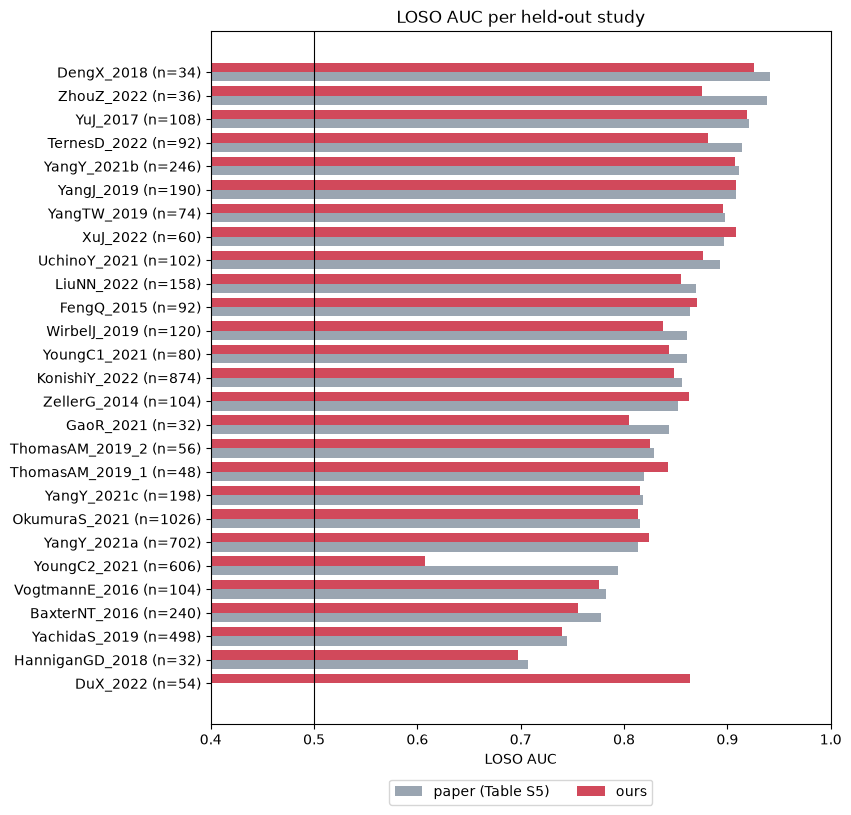

**Figure 2.** Studies are sorted by the paper's AUC. DuX_2022 (bottom) has no paper value. Our hardest study is YoungC2_2021 (AUC 0.61, 606 test samples). Small studies swing more: with 32 test samples, one CRC/control pair ranked the other way already moves the AUC by 1/256 ≈ 0.004, and the ranking of many pairs can change between two forests.

In [9]:
ordered = loso.sort_values("paper_auc", na_position="first")
positions = np.arange(len(ordered))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(positions - 0.2, ordered["paper_auc"].fillna(0), height=0.4, color="#9AA5B1", label="paper (Table S5)")
ax.barh(positions + 0.2, ordered["our_auc"], height=0.4, color="#D1495B", label="ours")
ax.set_yticks(positions, [f"{cohort} (n={row.n_test})" for cohort, row in ordered.iterrows()])
ax.axvline(0.5, color="black", linewidth=0.8)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("LOSO AUC")
ax.set_title("LOSO AUC per held-out study")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)

hardest = loso["our_auc"].idxmin()
show_figure(
    fig,
    "loso_per_cohort",
    f"Studies are sorted by the paper's AUC. DuX_2022 (bottom) has no paper value. Our hardest study is {hardest} "
    f"(AUC {loso.loc[hardest, 'our_auc']:.2f}, {loso.loc[hardest, 'n_test']} test samples). Small studies swing more: "
    f"with 32 test samples, one CRC/control pair ranked the other way already moves the AUC by 1/256 ≈ 0.004, "
    f"and the ranking of many pairs can change between two forests.",
)

### The two studies outside ±0.05

- **ZhouZ_2022** has only 36 test samples (18 CRC, 18 controls), so 324 CRC/control pairs decide its AUC. A handful of pairs ranked differently moves it by several hundredths. A gap of 0.06 there is within what two different forest implementations can produce.
- **YoungC2_2021** is different: 606 test samples, and our AUC is 0.19 below the paper's. The next cell checks how this study differs from the rest.

In [10]:
young = (labels["Cohort"] == "YoungC2_2021").to_numpy()
genera_without_young = prevalence_filter(relab[~young])
zero_share_young = (relab.loc[young, genera_without_young] == 0).to_numpy().mean()
zero_share_rest = (relab.loc[~young, genera_without_young] == 0).to_numpy().mean()
print(f"Share of zeros in the {len(genera_without_young)} training genera: YoungC2_2021 {zero_share_young:.0%}, all other studies {zero_share_rest:.0%}")

Share of zeros in the 300 training genera: YoungC2_2021 39%, all other studies 62%


YoungC2_2021 looks unlike the other studies: far fewer of its genera are zero. Something in how this study was sequenced or processed shifts its profiles, and a model trained on the other 26 studies transfers badly to it.

Before writing this down, we checked that the gap is not caused by one of our choices. Outside this notebook, the YoungC2_2021 AUC stayed between 0.58 and 0.61 with three other random seeds, with 500 trees and 9 or 37 features per split (the values SIAMCAT's tuning would try), with raw shares instead of normalized ones, and with the authors' approach of averaging ten fold models. Why the paper reaches 0.79 on this study is **an open question** to raise with the mentor or the authors.

## 5. Training set sizes against Figure S3C

The paper's Figure S3C prints a training size next to four LOSO results. Ours is simply all balanced samples minus the held-out study.

In [11]:
figure_s3c_train = pd.Series({"BaxterNT_2016": 5389, "HanniganGD_2018": 5576, "YangJ_2019": 5434, "ZellerG_2014": 5512}, name="paper_train_n")
train_sizes = pd.concat([figure_s3c_train, loso.loc[figure_s3c_train.index, "n_train"].rename("our_train_n")], axis=1)
train_sizes["difference"] = train_sizes["our_train_n"] - train_sizes["paper_train_n"]
train_sizes

,paper_train_n,our_train_n,difference
BaxterNT_2016,5389,5726,337
HanniganGD_2018,5576,5934,358
YangJ_2019,5434,5776,342
ZellerG_2014,5512,5862,350


Our training sets are larger, and by a constant factor: theirs are about 94% of ours for all four studies. Figure S3C's captions say its sizes are "averages per cross-validation fold", which suggests the authors' script trained the LOSO models with an inner cross-validation (that is what `Train.LOSO.rf.models.R` does), so each of their models saw only part of the training studies. We follow the paper's text, which describes one model trained on all other studies.

## 6. Bonus: cross-validation inside each single study

Table S5 also reports how well a model does **within** one study (`SCV`, study cross-validation): train and test on samples from the same study. There is no study effect to exploit here, but also far fewer samples to learn from.

For each study: filter and normalize on that study, then 10 times repeated, stratified 10-fold cross-validation, median over the repeats, as in notebook 01.

That is 27 × 100 = 2,700 small forests. Training them one after another takes about 13 minutes, mostly overhead, because each forest is tiny. So the 100 forests of a study are trained **at the same time**, one per CPU core, with `joblib.Parallel`, which starts one worker process per core. The results are identical, it just runs in about two minutes.

In [12]:
def within_study_auc(relab: pd.DataFrame, y: np.ndarray, seed: int) -> float:
    """10×10 stratified cross-validation inside one study; AUC of the median prediction over repeats."""
    genera = prevalence_filter(relab)
    features = apply_log_std(relab[genera], fit_log_std(relab[genera]))
    splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=seed).split(features, y))

    def fit_and_predict(train_idx: np.ndarray, test_idx: np.ndarray) -> np.ndarray:
        model = make_forest(seed, n_jobs=1)
        model.fit(features.iloc[train_idx], y[train_idx])
        return model.predict_proba(features.iloc[test_idx])[:, 1]

    fold_predictions = Parallel(n_jobs=-1)(delayed(fit_and_predict)(train_idx, test_idx) for train_idx, test_idx in splits)

    predictions = np.full((len(y), 10), np.nan)
    for split_number, ((_, test_idx), fold_prediction) in enumerate(zip(splits, fold_predictions)):
        predictions[test_idx, split_number // 10] = fold_prediction
    return roc_auc_score(y, np.median(predictions, axis=1))


start = time.perf_counter()
scv_rows = []
for cohort in cohorts:
    in_cohort = (labels["Cohort"] == cohort).to_numpy()
    scv_rows.append({
        "cohort": cohort,
        "n_test": int(in_cohort.sum()),
        "our_auc": within_study_auc(relab[in_cohort], labels.loc[in_cohort, "label"].to_numpy(), SEED),
    })
print(f"Trained {len(cohorts) * 100:,} forests in {time.perf_counter() - start:.0f} s")

scv = pd.DataFrame(scv_rows).set_index("cohort")
scv["paper_auc"] = paper_scv.reindex(scv.index)
scv["difference"] = scv["our_auc"] - scv["paper_auc"]
scv.round(4).to_csv(TABLES / "scv_auc.csv")
scv_mad = scv["difference"].abs().mean()
print(f"Within-study CV: mean absolute difference {scv_mad:.3f} over {scv['paper_auc'].notna().sum()} studies, "
      f"correlation {scv['our_auc'].corr(scv['paper_auc']):.2f}")

Trained 2,700 forests in 132 s
Within-study CV: mean absolute difference 0.030 over 27 studies, correlation 0.90


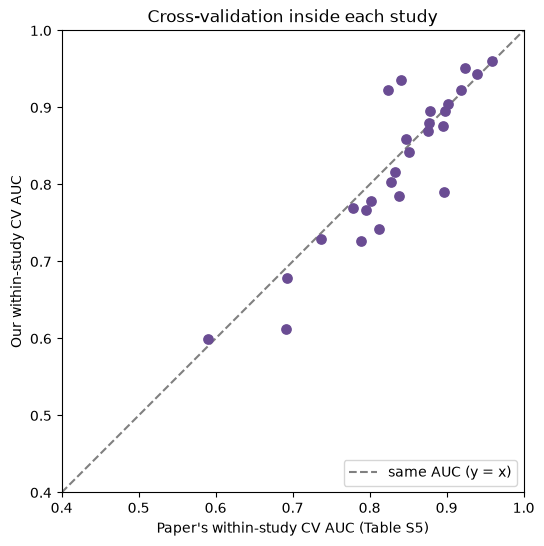

**Figure 3.** Each dot is one study. Our within-study AUCs differ from the paper's by 0.030 on average (correlation 0.90). The mean within-study AUC is 0.824 (paper 0.834), against a mean LOSO AUC of 0.836: a model trained on 26 other studies does better than one trained inside the study itself.

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(scv["paper_auc"], scv["our_auc"], color="#6A4C93", s=45, zorder=3)
ax.plot([0.4, 1], [0.4, 1], color="grey", linestyle="--", label="same AUC (y = x)")
ax.set_xlim(0.4, 1)
ax.set_ylim(0.4, 1)
ax.set_aspect("equal")
ax.set_xlabel("Paper's within-study CV AUC (Table S5)")
ax.set_ylabel("Our within-study CV AUC")
ax.set_title("Cross-validation inside each study")
ax.legend(loc="lower right")

show_figure(
    fig,
    "scv_vs_paper",
    f"Each dot is one study. Our within-study AUCs differ from the paper's by {scv_mad:.3f} on average "
    f"(correlation {scv['our_auc'].corr(scv['paper_auc']):.2f}). The mean within-study AUC is {scv['our_auc'].mean():.3f} "
    f"(paper {scv['paper_auc'].mean():.3f}), against a mean LOSO AUC of {loso['our_auc'].mean():.3f}: "
    f"a model trained on 26 other studies does {'better' if loso['our_auc'].mean() > scv['our_auc'].mean() else 'worse'} "
    f"than one trained inside the study itself.",
)

## 7. Checks

The two column and finiteness checks also run inside `loso_predict` for every held-out study.

In [14]:
paper = pd.read_excel(SHEETS / "mmc5.xlsx", skiprows=1).query("ML_approach == 'LOSO'")
assert len(paper) == 26
assert len(loso) == 27
assert loso["our_auc"].between(0.5, 1.0).all()
assert loso.loc["DuX_2022", "paper_auc"] != loso.loc["DuX_2022", "paper_auc"]
assert len(scv) == 27 and scv["our_auc"].notna().all()
print("All checks passed.")

All checks passed.


## What we learned

- Leave-one-study-out tests the real use case: a model trained on 26 studies, applied to a study it has never seen. Filtering and normalization are learned on the training studies only, so unlike notebook 01 there is no leakage here.
- Our 26 LOSO AUCs differ from Table S5 by **0.021 on average** (correlation 0.85), and 24 of 26 studies are within ±0.05. Our mean is 0.835, the paper's 0.851.
- **YoungC2_2021 is the one real outlier:** 0.61 against the paper's 0.79. The gap holds across seeds, tree settings and feature transforms. This study has far fewer zeros than the others (39% against 62%). The reason for the paper's higher value is an open question.
- Our training sets are about 6% larger than the sizes in Figure S3C, consistent with the authors' script training on inner folds, which the paper's text does not describe.
- Within single studies, cross-validation reaches a mean AUC of 0.824 (paper 0.834, mean difference 0.030). A model trained on 26 *other* studies (0.836) does slightly better than one trained inside the study itself, because pooling many studies gives far more training data.